# 11-6. 스케일 계수(k) 보정 연구

구간을 점예측 중심으로 k배 조정해 커버리지를 90%에 맞추는 보정을 **도입할지** 판단한다. 도입 기준 세 가지를 결과를 보기 전에 정하고 적용한다.

- **k (walk-forward)**: 예측 시점에 정답이 확정된 과거 예측의 '필요 배율'의 90% 분위수. 정의와 예시는 1절을 본다. 과거 예측만 쓰므로 실제 운영에서도 그대로 쓸 수 있다.
- **평가**: 22개 origin(88개 예측), 16개 조합. 변동성 적음/큼은 직전 8분기 Δy 표준편차의 22개 중앙값 기준이다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
var_std = vals.std()
NORIG, FIRST, LAST = 6, 35, 56
COLS = ["모델", "스케일", "구간", "origin", "h", "fc", "lo", "hi", "actual"]
res = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")        # 채점 origin 35~56 (11-1)
cal = pd.read_pickle("../cache/cache_107_calib_df.pkl")               # 캘리브레이션 origin 20~34 (11-1)
allrows = pd.concat([cal[COLS], res[COLS]], ignore_index=True)
COMBOS = sorted(res.groupby(["모델", "스케일", "구간"]).groups)
vol = pd.Series({o: np.diff(vals[:o])[-8:].std() / var_std for o in range(FIRST, LAST + 1)})      # origin별 직전 8분기 Δy 표준편차
HIGH = vol > vol.median()
print(f"변동성 중앙값 {vol.median():.3f}, 적음 {int((~HIGH).sum())}개 origin, 많음 {int(HIGH.sum())}개 origin")
print("변동성 많음 origin:", list(HIGH[HIGH].index))


def k_required(g, lg):
    # 각 예측이 구간 안에 들어오기 위해 필요한 배율
    fc, lo, hi, a = g["fc"].values, g["lo"].values, g["hi"].values, g["actual"].values
    if lg:
        fc, lo, hi, a = np.log(fc), np.log(lo), np.log(hi), np.log(a)
    up, dn = np.maximum(hi - fc, 1e-12), np.maximum(fc - lo, 1e-12)
    return np.where(a >= fc, (a - fc) / up, (fc - a) / dn)


def scaled(g, k, lg):
    fc, lo, hi = g["fc"].values, g["lo"].values, g["hi"].values
    if lg:
        return np.exp(np.log(fc) + k * (np.log(lo) - np.log(fc))), np.exp(np.log(fc) + k * (np.log(hi) - np.log(fc)))
    return fc + k * (lo - fc), fc + k * (hi - fc)


def quant(x, q=0.9):
    x = np.sort(x)
    return x[int(np.ceil(q * len(x))) - 1]


def past_k(g, lg, norig=NORIG, q=0.9):
    kr = k_required(g, lg)
    org, hh = g["origin"].values, g["h"].values
    out = {}
    for o in range(FIRST, LAST + 1):
        m = (org + hh) <= o
        out[o] = quant(kr[m], q) if len(np.unique(org[m])) >= norig else np.nan
    return pd.Series(out)


def label(key):
    return "/".join(key)


rows, kser = [], {}
for key in COMBOS:
    g = allrows[(allrows["모델"] == key[0]) & (allrows["스케일"] == key[1]) & (allrows["구간"] == key[2])].sort_values(["origin", "h"]).reset_index(drop=True)
    lg = key[1] == "로그"
    ks = past_k(g, lg)
    kser[key] = ks
    ev = g[g["origin"] >= FIRST].reset_index(drop=True)
    k = ev["origin"].map(ks).values
    a = ev["actual"].values
    l0, u0 = scaled(ev, 1.0, lg)
    l1, u1 = scaled(ev, k, lg)
    h0, h1 = (a >= l0) & (a <= u0), (a >= l1) & (a <= u1)
    e = ~ev["origin"].map(HIGH).values            # True = 변동성 적음
    rows.append({"모델": key[0], "스케일": key[1], "구간": key[2], "보정 불가 origin": int(ks.isna().sum()),
                 "커버리지 원래": h0.mean() * 100, "커버리지 k보정": h1.mean() * 100,
                 "원래 적음": h0[e].mean() * 100, "원래 많음": h0[~e].mean() * 100, "k보정 적음": h1[e].mean() * 100, "k보정 많음": h1[~e].mean() * 100,
                 "폭 원래": np.mean(u0 - l0) / var_std, "폭 k보정": np.mean(u1 - l1) / var_std,
                 "k(전체구간)": ks.mean(), "k(변동성 적은구간)": ks[~HIGH].mean(), "k(변동성 큰구간)": ks[HIGH].mean()})
R = pd.DataFrame(rows).set_index(["모델", "스케일", "구간"])
R["폭 배율"] = R["폭 k보정"] / R["폭 원래"]
print(f"조합 {len(R)}개, 평가 origin {FIRST}~{LAST} ({len(ev)}개 예측), 보정 불가 origin 합계 {int(R['보정 불가 origin'].sum())}")
print(f"변동성 적음 {int(e.sum())}개 예측, 많음 {int((~e).sum())}개 예측")
print(f"참고: 88개 예측의 이항 노이즈(1 표준편차) = {100 * np.sqrt(0.9 * 0.1 / 88):.1f}%p (origin끼리 겹쳐서 실제는 이보다 큼)")

변동성 중앙값 0.345, 적음 11개 origin, 많음 11개 origin
변동성 많음 origin: [39, 44, 48, 49, 50, 51, 52, 53, 54, 55, 56]
조합 16개, 평가 origin 35~56 (88개 예측), 보정 불가 origin 합계 0
변동성 적음 44개 예측, 많음 44개 예측
참고: 88개 예측의 이항 노이즈(1 표준편차) = 3.2%p (origin끼리 겹쳐서 실제는 이보다 큼)


## 1. 도입 기준 (결과를 보기 전에 정함)

| 기준 | 질문 | 도입 조건 |
|---|---|---|
| 1 | 보정 후 커버리지가 90%에 맞는가 | 85~95% 조합이 과반(8/16 이상)이고, 90%와의 평균 거리가 줄어든다 |
| 2 | 구간 점수가 개선되는가 | 낮아진 조합이 과반이고, 변화 중앙값이 음수다 |
| 3 | 상황별로 견고한가 | 8개 상황(변동성 적음/큼, 원/로그, 자체/리샘플링, h=1/h=4) 모두 구간 점수 변화 중앙값이 +10% 이하다 |

세 기준을 모두 충족할 때만 도입한다.

### k 계산 예시

- **쓰는 과거 예측**: 예측 시점 2020Q1(origin 36 (~2019Q4))이면 2019Q4까지 실제값이 확정된 예측만 쓴다. origin 35 (~2019Q3)는 h=1만, origin 34 (~2019Q2)는 h=1~2, origin 32 (~2018Q4) 이전은 h=1~4를 쓴다.
- **필요 배율**: 점예측 100, 구간 [90, 110]인 예측의 실제값이 112였다면 `(112 - 100) / (110 - 100) = 1.2`배가 필요했다(실제값이 104면 0.4).
- **k**: 필요 배율 10개가 `0.2, 0.4, 0.5, 0.7, 0.9, 1.0, 1.1, 1.5, 2.0, 3.0`이면 개수 기준 90%인 9번째 값 **k = 2.0**이다(과거 10개 중 9개가 구간 안에 들어옴). 극단값(3.0이 30.0)이 있어도 k는 변하지 않는다.
- **적용**: 지금 예측의 구간 [90, 110]에 k=2.0을 곱하면 [80, 120]이다.

### 구간 점수

구간 점수 = (상한 - 하한) + 20 x (구간 밖으로 벗어난 거리), `var_std`로 나눈다(20 = 2/α, α=0.10, 낮을수록 좋음).

- 예: 구간 [-1, 1]에 실제값 1.5이면 2 + 20 x 0.5 = **12**, 구간 [-2, 2]로 넓히면 **4**다. 실제값이 0.3이면 좁은 구간 2, 넓은 구간 4다.
- 구간 점수는 구간이 정확히 90%일 때 가장 낮다. 커버리지가 90%에 못 미치면 넓힐수록 좋아지고, 90%를 넘으면 넓힐수록 나빠진다.

In [2]:
def isc(l, u, a):
    return ((u - l) + 20 * np.maximum(l - a, 0) + 20 * np.maximum(a - u, 0)) / var_std


def combo_rows(key):
    return allrows[(allrows["모델"] == key[0]) & (allrows["스케일"] == key[1]) & (allrows["구간"] == key[2])].sort_values(["origin", "h"]).reset_index(drop=True)


def evaluate(ev, k, lg):
    l, u = scaled(ev, k, lg)
    a = ev["actual"].values
    return (a >= l) & (a <= u), u - l, isc(l, u, a)


parts = []
for key in COMBOS:
    ev = combo_rows(key)
    ev = ev[ev["origin"] >= FIRST].reset_index(drop=True)
    lg = key[1] == "로그"
    k = ev["origin"].map(kser[key]).values
    h0, w0, i0 = evaluate(ev, 1.0, lg)
    h1, w1, i1 = evaluate(ev, k, lg)
    parts.append(pd.DataFrame({"모델": key[0], "스케일": key[1], "구간": key[2], "origin": ev["origin"].values, "h": ev["h"].values,
                               "hit0": h0, "hit1": h1, "is0": i0, "is1": i1, "high": ev["origin"].map(HIGH).values}))
D = pd.concat(parts, ignore_index=True)
CK = ["모델", "스케일", "구간"]
print(f"16개 조합, 예측 {len(D) // 16}개 x 16 (origin {FIRST}~{LAST})")
Q3 = D.groupby(CK).agg(**{"구간 점수 원래": ("is0", "mean"), "구간 점수 k보정": ("is1", "mean")})

16개 조합, 예측 88개 x 16 (origin 35~56)


## 2. 기준 1: 보정 후 커버리지가 90%에 맞는가

85~95%를 '맞음', 95% 초과를 과다 보정으로 본다.

In [3]:
def cov_stats(mask, name):
    c = D[mask].groupby(CK)[["hit0", "hit1"]].mean() * 100
    return {"구분": name, "평균 커버리지 전": c["hit0"].mean(), "평균 커버리지 후": c["hit1"].mean(),
            "90% 거리 전": (c["hit0"] - 90).abs().mean(), "90% 거리 후": (c["hit1"] - 90).abs().mean(),
            "85~95% 조합 전": int(c["hit0"].between(85, 95).sum()), "85~95% 조합 후": int(c["hit1"].between(85, 95).sum()),
            "95% 초과 조합 후": int((c["hit1"] > 95).sum())}


allm = D["h"] > 0
S1 = pd.DataFrame([cov_stats(allm, "전체"), cov_stats(~D["high"], "변동성 적음"), cov_stats(D["high"], "변동성 큼")]).set_index("구분")
display(S1.round(1))
C = D.groupby(CK)[["hit0", "hit1"]].mean() * 100
C.columns = ["보정 전", "k 보정"]
display(C.sort_values("보정 전").round(1))

,평균 커버리지 전,평균 커버리지 후,90% 거리 전,90% 거리 후,85~95% 조합 전,85~95% 조합 후,95% 초과 조합 후
구분,,,,,,,
전체,74.0,89.1,16.0,5.5,2,9,4
변동성 적음,56.7,79.4,33.3,13.9,0,2,2
변동성 큼,91.3,98.9,8.7,8.9,2,2,14


,,,보정 전,k 보정
모델,스케일,구간,,
auto_arima,원,자체,61.4,87.5
AR단독,원,리샘플링,63.6,92.0
SV,원,자체,64.8,85.2
AR단독,원,자체,65.9,78.4
auto_arima,원,리샘플링,69.3,90.9
AR단독,로그,리샘플링,70.5,89.8
auto_arima,로그,리샘플링,71.6,89.8
SV,로그,자체,72.7,89.8
GARCH,로그,자체,73.9,90.9


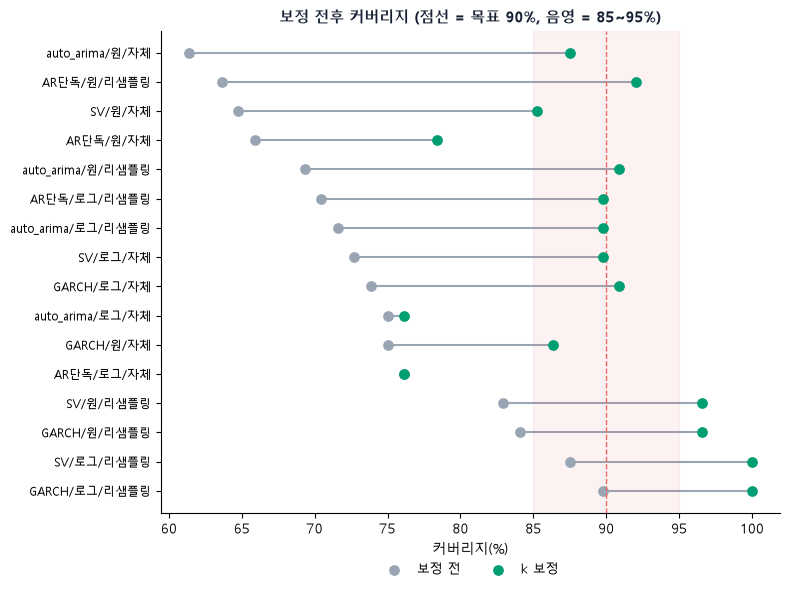

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
od = C.sort_values("보정 전").index
for i, key in enumerate(od):
    x0, x1 = C.loc[key, "보정 전"], C.loc[key, "k 보정"]
    ax.plot([x0, x1], [i, i], color="#9AA5B4", linewidth=1.5, zorder=1)
    ax.scatter(x0, i, color="#9AA5B4", s=45, zorder=2, label="보정 전" if i == 0 else None)
    ax.scatter(x1, i, color="#009E73", s=45, zorder=3, label="k 보정" if i == 0 else None)
ax.axvline(90, color="#EF6461", linestyle="--", linewidth=1)
ax.axvspan(85, 95, color="#EF6461", alpha=0.08)
ax.set_yticks(range(len(od)))
ax.set_yticklabels([label(k) for k in od], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("커버리지(%)")
ax.set_title("보정 전후 커버리지 (점선 = 목표 90%, 음영 = 85~95%)", fontsize=11, fontweight="bold", color="#172033")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 3. 기준 2: 구간 점수가 개선되는가

변화(%)가 음수면 좋아진 것이다.

In [5]:
Q3["변화(%)"] = 100 * (Q3["구간 점수 k보정"] / Q3["구간 점수 원래"] - 1)
display(Q3.sort_values("구간 점수 원래").round(2))
print(f"구간 점수가 낮아진 조합 {int((Q3['변화(%)'] < 0).sum())}/16, 높아진 조합 {int((Q3['변화(%)'] > 0).sum())}/16, 변화 중앙값 {Q3['변화(%)'].median():+.1f}%")

구간 점수 원래  구간 점수 k보정   변화(%)
모델         스케일 구간                               
SV         원   리샘플링      5.15       8.27   60.49
auto_arima 원   리샘플링      5.77       5.60   -2.91
AR단독       원   자체        6.09       5.18  -14.89
               리샘플링      6.17       5.83   -5.46
auto_arima 원   자체        6.33       5.05  -20.26
SV         로그  자체        6.38       7.47   17.12
GARCH      원   자체        6.39       6.57    2.73
SV         원   자체        6.58       5.54  -15.76
GARCH      원   리샘플링      6.82      11.25   64.98
AR단독       로그  자체        7.17       7.87    9.77
auto_arima 로그  자체        7.28       8.15   11.98
AR단독       로그  리샘플링      7.74      14.31   84.84
auto_arima 로그  리샘플링      8.09      15.17   87.45
GARCH      로그  자체        8.37      21.21  153.52
SV         로그  리샘플링      8.59      47.17  448.95
GARCH      로그  리샘플링     20.04     158.24  689.56

구간 점수가 낮아진 조합 5/16, 높아진 조합 11/16, 변화 중앙값 +14.5%


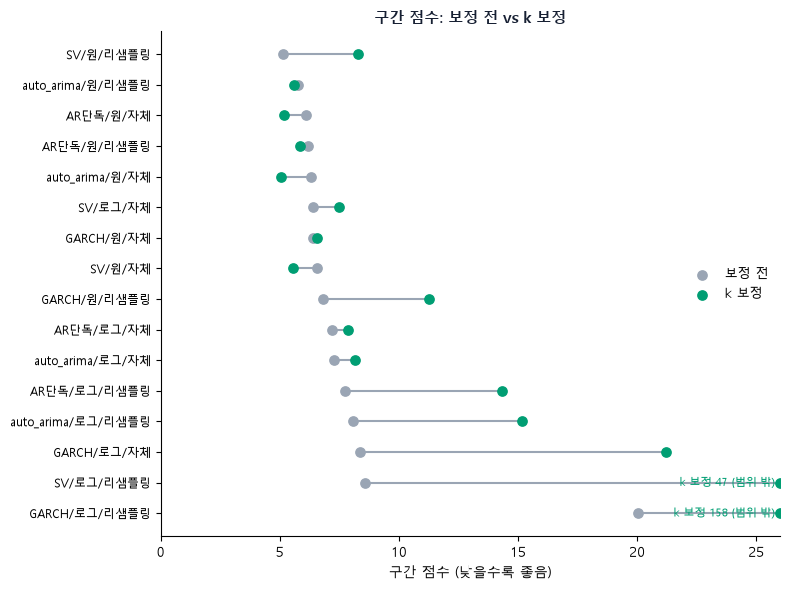

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
od = Q3.sort_values("구간 점수 원래").index
for i, key in enumerate(od):
    x0, x1 = Q3.loc[key, "구간 점수 원래"], Q3.loc[key, "구간 점수 k보정"]
    ax.plot([x0, min(x1, 26)], [i, i], color="#9AA5B4", linewidth=1.5, zorder=1)
    ax.scatter(x0, i, color="#9AA5B4", s=45, zorder=2, label="보정 전" if i == 0 else None)
    ax.scatter(min(x1, 26), i, color="#009E73", s=45, zorder=3, label="k 보정" if i == 0 else None)
    if x1 > 26:
        ax.annotate(f"k 보정 {x1:.0f} (범위 밖)", (26, i), xytext=(-4, 0), textcoords="offset points", ha="right", va="center", fontsize=8, color="#009E73")
ax.set_xlim(0, 26)
ax.set_yticks(range(len(od)))
ax.set_yticklabels([label(k) for k in od], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("구간 점수 (낮을수록 좋음)")
ax.set_title("구간 점수: 보정 전 vs k 보정", fontsize=11, fontweight="bold", color="#172033")
ax.legend(frameon=False, fontsize=9, loc="center right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 4. 기준 3: 상황별로 견고한가

8개 상황의 구간 점수 변화(조합별 변화의 중앙값)를 본다.

In [7]:
def change(rows, keys=None):
    g = rows.groupby(CK).agg(a=("is0", "mean"), b=("is1", "mean"))
    if keys is not None:
        g = g[g.index.isin(keys)]
    return 100 * (g["b"] / g["a"] - 1)


idx = D.set_index(CK).index
sits = [("변동성 적음", change(D[~D["high"]])), ("변동성 큼", change(D[D["high"]])),
        ("원 스케일", change(D[D["스케일"] == "원"])), ("로그 스케일", change(D[D["스케일"] == "로그"])),
        ("자체 구간", change(D[D["구간"] == "자체"])), ("리샘플링 구간", change(D[D["구간"] == "리샘플링"])),
        ("h=1", change(D[D["h"] == 1])), ("h=4", change(D[D["h"] == 4]))]
S3 = pd.DataFrame([{"상황": n, "조합 수": len(c), "악화 조합 수": int((c > 0).sum()), "변화 중앙값(%)": c.median(), "+10% 이하": "예" if c.median() <= 10 else "아니오"} for n, c in sits]).set_index("상황")
display(S3.round(1))

,조합 수,악화 조합 수,변화 중앙값(%),+10% 이하
상황,,,,
변동성 적음,16,4,-16.0,예
변동성 큼,16,16,85.6,아니오
원 스케일,8,3,-4.2,예
로그 스케일,8,8,86.1,아니오
자체 구간,8,5,6.2,예
리샘플링 구간,8,6,74.9,아니오
h=1,16,13,20.9,아니오
h=4,16,10,14.0,아니오


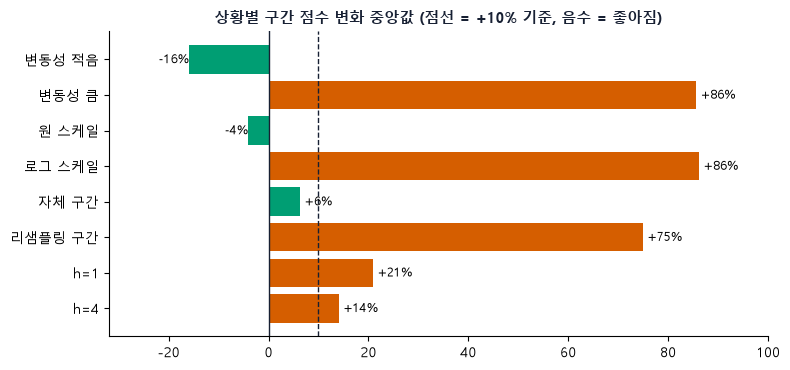

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
v = S3["변화 중앙값(%)"]
ax.barh(range(len(v)), v.values, color=["#009E73" if x <= 10 else "#D55E00" for x in v.values])
ax.axvline(10, color="#172033", linestyle="--", linewidth=1)
ax.axvline(0, color="#172033", linewidth=1)
ax.set_xlim(-32, 100)
ax.set_yticks(range(len(v)))
ax.set_yticklabels(v.index)
ax.invert_yaxis()
for i, x in enumerate(v.values):
    ax.text(x, i, f" {x:+.0f}%", va="center", ha="left" if x >= 0 else "right", fontsize=9)
ax.set_title("상황별 구간 점수 변화 중앙값 (점선 = +10% 기준, 음수 = 좋아짐)", fontsize=10.5, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 5. 판정

In [9]:
c = D.groupby(CK)[["hit0", "hit1"]].mean() * 100
ok1 = int(c["hit1"].between(85, 95).sum()) >= 8 and (c["hit1"] - 90).abs().mean() < (c["hit0"] - 90).abs().mean()
ok2 = int((Q3["변화(%)"] < 0).sum()) >= 9 and Q3["변화(%)"].median() < 0
ok3 = bool((S3["변화 중앙값(%)"] <= 10).all())
J = pd.DataFrame([
    {"기준": "1. 보정 후 커버리지가 90%에 맞는가", "결과": f"85~95% 조합 {int(c['hit1'].between(85, 95).sum())}/16, 90% 거리 {(c['hit0'] - 90).abs().mean():.1f} -> {(c['hit1'] - 90).abs().mean():.1f}%p", "판정": "충족" if ok1 else "미충족"},
    {"기준": "2. 구간 점수가 개선되는가", "결과": f"낮아진 조합 {int((Q3['변화(%)'] < 0).sum())}/16, 중앙값 {Q3['변화(%)'].median():+.1f}%", "판정": "충족" if ok2 else "미충족"},
    {"기준": "3. 상황별로 견고한가", "결과": f"+10% 초과 상황 {int((S3['변화 중앙값(%)'] > 10).sum())}/8 ({', '.join(S3.index[S3['변화 중앙값(%)'] > 10])})", "판정": "충족" if ok3 else "미충족"}]).set_index("기준")
display(J)
print("도입 판정:", "도입" if (ok1 and ok2 and ok3) else "도입하지 않음 (세 기준을 모두 충족하지 못함)")

,결과,판정
기준,,
1. 보정 후 커버리지가 90%에 맞는가,"85~95% 조합 9/16, 90% 거리 16.0 -> 5.5%p",충족
2. 구간 점수가 개선되는가,"낮아진 조합 5/16, 중앙값 +14.5%",미충족
3. 상황별로 견고한가,"+10% 초과 상황 5/8 (변동성 큼, 로그 스케일, 리샘플링 구간, h=1, h=4)",미충족


도입 판정: 도입하지 않음 (세 기준을 모두 충족하지 못함)


## 6. 결론

**세 기준 중 기준 1만 충족해서 스케일 계수 보정은 도입하지 않는다.**

| 기준 | 결과 | 판정 |
|---|---|---|
| 1. 90%에 맞는가 | 85~95% 조합 2개에서 9개로, 90%와의 거리 16.0에서 5.5%p | 충족 |
| 2. 구간 점수 개선 | 낮아진 조합 5/16, 변화 중앙값 +14.5% | 미충족 |
| 3. 상황별 견고함 | +10% 초과 상황 5/8 | 미충족 |

- **기준 1**: 평균 커버리지 74.0%에서 89.1%지만, 4개 조합은 95% 초과 과다 보정이고 변동성 큼 구간은 14/16이 95%를 넘는다.
- **기준 2**: 좋아진 5개는 원 스케일 자체 구간(-3~-20%)이고, 로그 리샘플링은 +85~690%로 크게 나빠졌다.
- **기준 3**: 변동성 큼(+85.6%), 로그(+86.1%), 리샘플링(+74.9%), h=1(+20.9%), h=4(+14.0%)가 기준을 넘는다. 변동성 적음(-16.0%), 원(-4.2%), 자체(+6.2%)는 기준 안이다.
- **부록**: 폭은 중앙값 2.2배로 늘고, 필터의 3단계를 보정 후 구간 점수로 바꾸면 선택이 AR단독 원 자체로 바뀐다.
- 한계: 22개 origin이 겹치고 한 변수의 결과이며, 변동성 큼 구간(origin 48 (~2022Q4) ~ 56 (~2024Q4))은 급등 한 번의 사례다.

## 부록. 보조 결과

### A-1. 폭 비용

폭 = 구간 폭 / `var_std`. k(전체구간)는 22개 origin의 k 평균, 나머지 두 열은 해당 origin의 k 평균이다.

In [10]:
W = R[["커버리지 원래", "k(전체구간)", "k(변동성 적은구간)", "k(변동성 큰구간)", "폭 원래", "폭 k보정", "폭 배율", "커버리지 k보정"]].sort_values("k(전체구간)")
display(W.round(2))
from scipy.stats import spearmanr
print(f"기본 커버리지와 k(전체구간)의 Spearman: {spearmanr(R['커버리지 원래'], R['k(전체구간)'])[0]:.2f}")
print(f"폭 배율: 중앙값 {R['폭 배율'].median():.2f}, 최소 {R['폭 배율'].min():.2f}, 최대 {R['폭 배율'].max():.2f}")
print(f"k(전체구간)가 1보다 작은 조합(보정이 구간을 줄임): {int((R['k(전체구간)'] < 1).sum())}/16, 1.5 이상: {int((R['k(전체구간)'] >= 1.5).sum())}/16")
sc_ = R.groupby("스케일")[["k(전체구간)", "폭 배율"]].mean().round(2)
gp_ = R.groupby("구간")[["k(전체구간)", "폭 배율"]].mean().round(2)
display(sc_)
display(gp_)

커버리지 원래  k(전체구간)  k(변동성 적은구간)  k(변동성 큰구간)   폭 원래   폭 k보정  \
모델         스케일 구간                                                               
AR단독       로그  자체      76.14     1.17         1.04        1.29   4.03    5.40   
auto_arima 로그  자체      75.00     1.20         1.05        1.34   4.07    5.71   
AR단독       원   자체      65.91     1.54         1.48        1.59   1.73    2.68   
           로그  리샘플링    70.45     1.67         1.64        1.69   5.35   13.69   
auto_arima 로그  리샘플링    71.59     1.69         1.70        1.69   5.71   14.57   
           원   자체      61.36     1.73         1.70        1.75   1.71    2.95   
GARCH      로그  리샘플링    89.77     1.79         2.08        1.51  19.59  158.24   
auto_arima 원   리샘플링    69.32     1.84         1.77        1.91   2.14    3.99   
GARCH      원   자체      75.00     1.88         1.80        1.96   2.46    4.69   
SV         로그  자체      72.73     1.92         1.97        1.87   3.00    7.01   
           원   자체      64.77     1.94         1.85        2.02   1.80    3.53   
GARCH      로그  자체      73.86     1.94         1.93        1.95   5.43   20.91   
AR단독       원   리샘플링    63.64     2.27         2.25        2.30   2.10    4.78   
GARCH      원   리샘플링    84.09     2.29         2.64        1.93   5.01   10.91   
SV         로그  리샘플링    87.50     2.35         2.86        1.83   8.05   47.17   
           원   리샘플링    82.95     2.58         3.21        1.96   3.48    8.06   

                     폭 배율  커버리지 k보정  
모델         스케일 구간                    
AR단독       로그  자체    1.34     76.14  
auto_arima 로그  자체    1.40     76.14  
AR단독       원   자체    1.55     78.41  
           로그  리샘플링  2.56     89.77  
auto_arima 로그  리샘플링  2.55     89.77  
           원   자체    1.73     87.50  
GARCH      로그  리샘플링  8.08    100.00  
auto_arima 원   리샘플링  1.86     90.91  
GARCH      원   자체    1.91     86.36  
SV         로그  자체    2.34     89.77  
           원   자체    1.97     85.23  
GARCH      로그  자체    3.85     90.91  
AR단독       원   리샘플링  2.28     92.05  
GARCH      원   리샘플링  2.18     96.59  
SV         로그  리샘플링  5.86    100.00  
           원   리샘플링  2.32     96.59

기본 커버리지와 k(전체구간)의 Spearman: 0.23
폭 배율: 중앙값 2.23, 최소 1.34, 최대 8.08
k(전체구간)가 1보다 작은 조합(보정이 구간을 줄임): 0/16, 1.5 이상: 14/16


,k(전체구간),폭 배율
스케일,,
로그,1.72,3.50
원,2.01,1.97


,k(전체구간),폭 배율
구간,,
리샘플링,2.06,3.46
자체,1.66,2.01


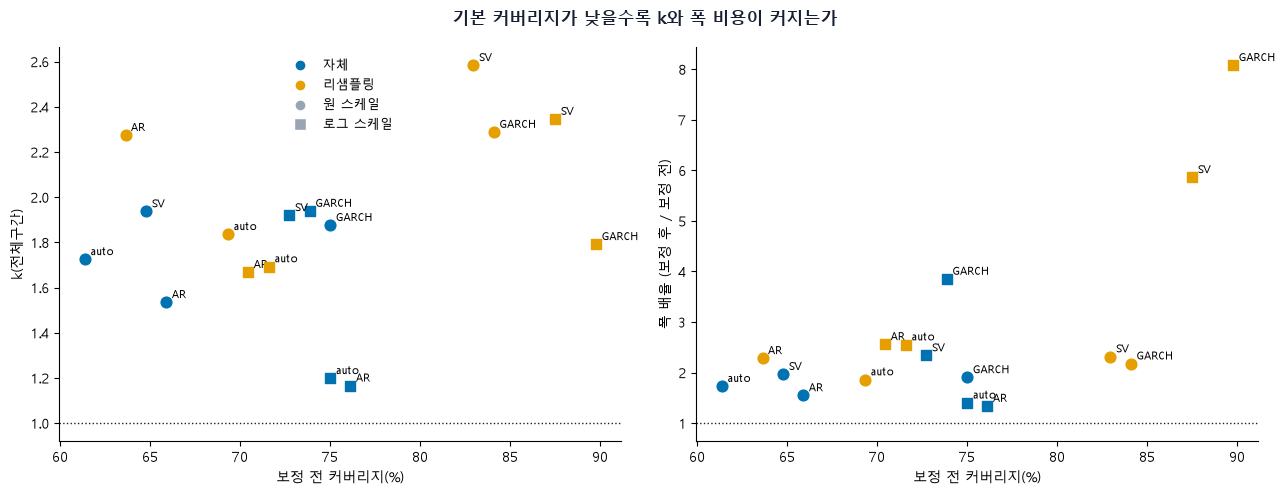

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
col = {"자체": "#0072B2", "리샘플링": "#E69F00"}
mk = {"원": "o", "로그": "s"}
for ax, (yc, yl) in zip(axes, [("k(전체구간)", "k(전체구간)"), ("폭 배율", "폭 배율 (보정 후 / 보정 전)")]):
    for key, r in R.iterrows():
        ax.scatter(r["커버리지 원래"], r[yc], color=col[key[2]], marker=mk[key[1]], s=60, zorder=3)
        ax.annotate(key[0].replace("auto_arima", "auto").replace("AR단독", "AR"), (r["커버리지 원래"], r[yc]), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax.axhline(1, color="#172033", linestyle=":", linewidth=1)
    ax.set_xlabel("보정 전 커버리지(%)")
    ax.set_ylabel(yl)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
from matplotlib.lines import Line2D
axes[0].legend(handles=[Line2D([], [], marker="o", color="w", markerfacecolor="#0072B2", markersize=8, label="자체"),
                        Line2D([], [], marker="o", color="w", markerfacecolor="#E69F00", markersize=8, label="리샘플링"),
                        Line2D([], [], marker="o", color="w", markerfacecolor="#9AA5B4", markersize=8, label="원 스케일"),
                        Line2D([], [], marker="s", color="w", markerfacecolor="#9AA5B4", markersize=8, label="로그 스케일")], frameon=False, fontsize=9)
fig.suptitle("기본 커버리지가 낮을수록 k와 폭 비용이 커지는가", fontsize=12, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()

### A-2. k의 변화

`11-5`의 2단계 통과 후보의 k(전체구간)를 origin별로 그린다(회색 음영 = 변동성 큰 origin).

CRPS ±10% 통과 9개 -> MSE ±10% 통과 7개: ['SV/원/자체', 'GARCH/원/자체', 'AR단독/원/자체', 'SV/로그/자체', 'AR단독/원/리샘플링', 'SV/원/리샘플링', 'GARCH/원/리샘플링']


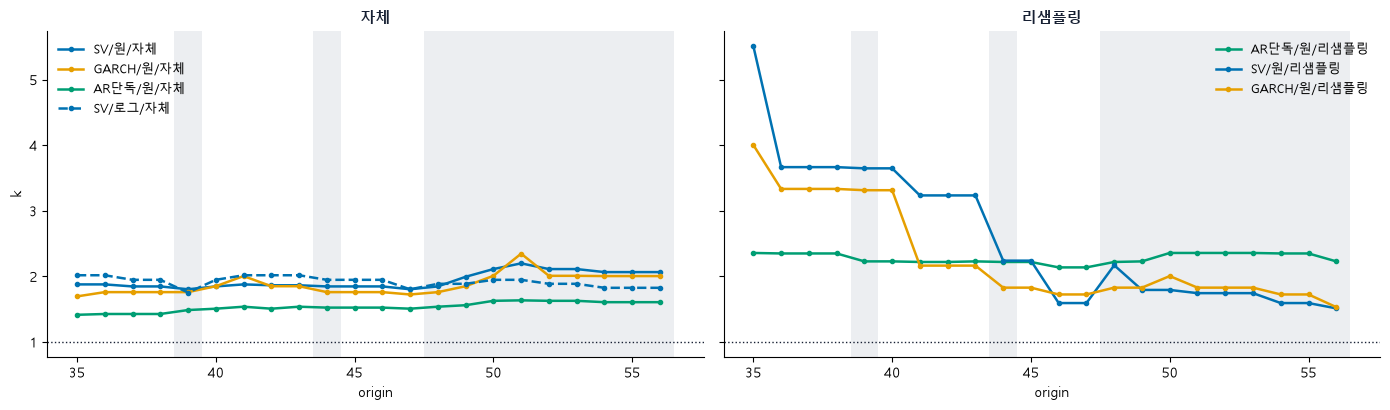

In [12]:
g_ = res.groupby(["모델", "스케일", "구간"])
X4 = pd.DataFrame({"crps": g_.apply(lambda d: d.groupby("origin")["crps_ensemble"].mean().mean()), "MSE": g_["MSE"].mean()})
s1_ = X4[X4["crps"] <= 1.10 * X4["crps"].min()]
s2_ = s1_[s1_["MSE"] <= 1.10 * s1_["MSE"].min()]
sel = list(s2_.sort_values("crps").index)
print(f"CRPS ±10% 통과 {len(s1_)}개 -> MSE ±10% 통과 {len(s2_)}개:", [label(k) for k in sel])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, g_name in zip(axes, ["자체", "리샘플링"]):
    for o in HIGH[HIGH].index:
        ax.axvspan(o - 0.5, o + 0.5, color="#9AA5B4", alpha=0.18, linewidth=0)
    for key in [k for k in sel if k[2] == g_name]:
        ax.plot(kser[key].index, kser[key].values, marker="o", ms=3, linewidth=1.8, color={"SV": "#0072B2", "GARCH": "#E69F00", "AR단독": "#009E73"}[key[0]],
                linestyle="--" if key[1] == "로그" else "-", label=label(key))
    ax.axhline(1, color="#172033", linestyle=":", linewidth=1)
    ax.set_title(g_name, fontsize=11, fontweight="bold", color="#172033")
    ax.set_xlabel("origin")
    ax.legend(frameon=False, fontsize=9, loc="upper left" if g_name == "자체" else "upper right")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[0].set_ylabel("k")
fig.tight_layout()
plt.show()

### A-3. 공통 k vs h별 k

h별 k는 origin 6개 이상일 때만 쓰고 부족하면 공통 k로 대체한다.

In [13]:
def kh_series(g, lg, h):
    gh = g[g["h"] == h]
    kr = k_required(gh, lg)
    org = gh["origin"].values
    out = {}
    for o in range(FIRST, LAST + 1):
        m = (org + h) <= o
        out[o] = quant(kr[m]) if m.sum() >= NORIG else np.nan
    return pd.Series(out)


rows4, fb = [], []
for key in COMBOS:
    g = combo_rows(key)
    lg = key[1] == "로그"
    ev = g[g["origin"] >= FIRST].reset_index(drop=True)
    kc = ev["origin"].map(kser[key]).values
    khs = {h: kh_series(g, lg, h) for h in range(1, 5)}
    kh = np.array([khs[h][o] for o, h in zip(ev["origin"], ev["h"])])
    nan = np.isnan(kh)
    kh = np.where(nan, kc, kh)
    fb.append(pd.Series({h: np.isnan(np.array([khs[h][o] for o in ev["origin"][ev["h"] == h]])).mean() * 100 for h in range(1, 5)}, name=key))
    hc, wc, ic = evaluate(ev, kc, lg)
    hh, wh, ih = evaluate(ev, kh, lg)
    h0 = evaluate(ev, 1.0, lg)[0]
    rows4.append({"모델": key[0], "스케일": key[1], "구간": key[2], "커버리지 원래": h0.mean() * 100, "커버리지 공통": hc.mean() * 100, "커버리지 h별": hh.mean() * 100,
                  "구간 점수 공통": ic.mean(), "구간 점수 h별": ih.mean(), "h별 대체 비율(%)": nan.mean() * 100})
Q4 = pd.DataFrame(rows4).set_index(["모델", "스케일", "구간"])
Q4["점수 변화(%)"] = 100 * (Q4["구간 점수 h별"] / Q4["구간 점수 공통"] - 1)
display(Q4.round(2).sort_values("커버리지 원래"))
sm = pd.DataFrame({"공통 k": [Q4["커버리지 공통"].mean(), (Q4["커버리지 공통"] - 90).abs().mean(), Q4["구간 점수 공통"].mean()],
                   "h별 k": [Q4["커버리지 h별"].mean(), (Q4["커버리지 h별"] - 90).abs().mean(), Q4["구간 점수 h별"].mean()]},
                  index=["16개 평균 커버리지(%)", "90%와의 평균 거리(%p)", "16개 평균 구간 점수"])
display(sm.round(2))
print(f"h별 k가 구간 점수를 낮춘 조합 {int((Q4['점수 변화(%)'] < 0).sum())}/16, 높인 조합 {int((Q4['점수 변화(%)'] > 0).sum())}/16, 중앙값 {Q4['점수 변화(%)'].median():+.1f}%")
print("h별 k를 쓰지 못하고 공통 k로 대체한 비율(%, 16개 평균):")
display(pd.DataFrame(fb).mean().round(1).to_frame("대체 비율(%)").T)

,,,커버리지 원래,커버리지 공통,커버리지 h별,구간 점수 공통,구간 점수 h별,h별 대체 비율(%),점수 변화(%)
모델,스케일,구간,,,,,,,
auto_arima,원,자체,61.36,87.50,86.36,5.05,5.13,0.00,1.69
AR단독,원,리샘플링,63.64,92.05,90.91,5.83,6.03,10.23,3.39
SV,원,자체,64.77,85.23,85.23,5.54,5.59,0.00,0.85
AR단독,원,자체,65.91,78.41,80.68,5.18,5.31,0.00,2.53
auto_arima,원,리샘플링,69.32,90.91,90.91,5.60,5.63,10.23,0.49
AR단독,로그,리샘플링,70.45,89.77,88.64,14.31,12.81,10.23,-10.47
auto_arima,로그,리샘플링,71.59,89.77,88.64,15.17,13.81,10.23,-8.95
SV,로그,자체,72.73,89.77,92.05,7.47,7.74,0.00,3.61
GARCH,로그,자체,73.86,90.91,90.91,21.21,18.41,0.00,-13.22


,공통 k,h별 k
16개 평균 커버리지(%),89.13,88.78
90%와의 평균 거리(%p),5.50,5.82
16개 평균 구간 점수,20.81,128.69


h별 k가 구간 점수를 낮춘 조합 3/16, 높인 조합 13/16, 중앙값 +2.1%
h별 k를 쓰지 못하고 공통 k로 대체한 비율(%, 16개 평균):


,1,2,3,4
대체 비율(%),0.0,2.3,6.8,11.4


### A-4. 보정이 구간 점수 순위를 바꾸나

구간 점수 순위의 보정 전후 변화와, `11-5` 필터의 3단계를 보정 후 값으로 바꿨을 때의 선택. 커버리지가 보정으로 맞춰지는 순환 때문에 기존 세 지표 순위의 변화는 비교하지 않았다.

In [14]:
from scipy.stats import spearmanr
rk = pd.DataFrame({"구간 점수 원래": Q3["구간 점수 원래"], "구간 점수 k보정": Q3["구간 점수 k보정"]})
rk["순위 원래"] = rk["구간 점수 원래"].rank().astype(int)
rk["순위 k보정"] = rk["구간 점수 k보정"].rank().astype(int)
rk["순위 변화"] = rk["순위 원래"] - rk["순위 k보정"]
display(rk.sort_values("순위 원래").round(3))
print(f"순위 Spearman {spearmanr(rk['순위 원래'], rk['순위 k보정'])[0]:.3f}, 순위가 바뀐 조합 {int((rk['순위 변화'] != 0).sum())}/16")
print("상위 3개 (보정 없음):", [label(k) for k in rk.sort_values("순위 원래").index[:3]])
print("상위 3개 (k 보정):", [label(k) for k in rk.sort_values("순위 k보정").index[:3]])

구간 점수 원래  구간 점수 k보정  순위 원래  순위 k보정  순위 변화
모델         스케일 구간                                             
SV         원   리샘플링     5.153      8.270      1      10     -9
auto_arima 원   리샘플링     5.771      5.603      2       4     -2
AR단독       원   자체       6.090      5.183      3       2      1
               리샘플링     6.167      5.831      4       5     -1
auto_arima 원   자체       6.327      5.045      5       1      4
SV         로그  자체       6.381      7.474      6       7     -1
GARCH      원   자체       6.393      6.567      7       6      1
SV         원   자체       6.576      5.540      8       3      5
GARCH      원   리샘플링     6.818     11.248      9      11     -2
AR단독       로그  자체       7.173      7.874     10       8      2
auto_arima 로그  자체       7.281      8.153     11       9      2
AR단독       로그  리샘플링     7.744     14.313     12      12      0
auto_arima 로그  리샘플링     8.091     15.167     13      13      0
GARCH      로그  자체       8.367     21.211     14      14      0
SV         로그  리샘플링     8.592     47.167     15      15      0
GARCH      로그  리샘플링    20.042    158.243     16      16      0

순위 Spearman 0.791, 순위가 바뀐 조합 11/16
상위 3개 (보정 없음): ['SV/원/리샘플링', 'auto_arima/원/리샘플링', 'AR단독/원/자체']
상위 3개 (k 보정): ['auto_arima/원/자체', 'AR단독/원/자체', 'SV/원/자체']


In [15]:
g2 = res.groupby(["모델", "스케일", "구간"])
Mf = pd.DataFrame({"crps": g2.apply(lambda d: d.groupby("origin")["crps_ensemble"].mean().mean()), "MSE": g2["MSE"].mean()})
Mf["IS 원래"], Mf["IS k보정"] = Q3["구간 점수 원래"], Q3["구간 점수 k보정"]
Mf["커버리지"] = g2["적중"].mean()


def cascade(ic, tc=0.10, tm=0.10, ti=0.10):
    s1 = Mf[Mf["crps"] <= (1 + tc) * Mf["crps"].min()]
    s2 = s1[s1["MSE"] <= (1 + tm) * s1["MSE"].min()]
    s3 = s2[s2[ic] <= (1 + ti) * s2[ic].min()]
    return len(s1), len(s2), len(s3), (s3["커버리지"].idxmax() if len(s3) else None)


import itertools
out = []
for ic in ["IS 원래", "IS k보정"]:
    n1, n2, n3, p = cascade(ic)
    cnt = pd.Series(["/".join(cascade(ic, *t)[3]) if cascade(ic, *t)[3] else "없음" for t in itertools.product([0.05, 0.10, 0.20], repeat=3)]).value_counts()
    out.append({"3단계 구간 점수": ic, "통과(1/2/3단계)": f"{n1}/{n2}/{n3}", "±10% 선택": "/".join(p) if p else "없음", "27가지 선택 빈도": ", ".join(f"{k} {v}" for k, v in cnt.items())})
display(pd.DataFrame(out).set_index("3단계 구간 점수"))

,통과(1/2/3단계),±10% 선택,27가지 선택 빈도
3단계 구간 점수,,,
IS 원래,9/7/1,SV/원/리샘플링,SV/원/리샘플링 27
IS k보정,9/7/2,AR단독/원/자체,"AR단독/원/자체 14, SV/원/자체 6, auto_arima/원/리샘플링 4, ..."


### A-5. 정답을 보고 k를 정하면

in-sample k(평가 88개 전체로 정함)는 정답을 본 값이라 낙관적이다.

In [16]:
rows6 = []
for key in COMBOS:
    g = combo_rows(key)
    lg = key[1] == "로그"
    ev = g[g["origin"] >= FIRST].reset_index(drop=True)
    kin = quant(k_required(ev, lg))
    kw = ev["origin"].map(kser[key]).values
    hi_, wi_, ii_ = evaluate(ev, kin, lg)
    hw_, ww_, iw_ = evaluate(ev, kw, lg)
    rows6.append({"모델": key[0], "스케일": key[1], "구간": key[2], "k in-sample": kin, "k(전체구간)": float(np.mean(kw)),
                  "커버리지 in-sample": hi_.mean() * 100, "커버리지 k보정": hw_.mean() * 100, "구간 점수 in-sample": ii_.mean(), "구간 점수 k보정": iw_.mean()})
Q6 = pd.DataFrame(rows6).set_index(["모델", "스케일", "구간"])
Q6["점수 차이(%)"] = 100 * (Q6["구간 점수 k보정"] / Q6["구간 점수 in-sample"] - 1)
display(Q6.round(2).sort_values("점수 차이(%)", ascending=False))
print(f"in-sample 평균 커버리지 {Q6['커버리지 in-sample'].mean():.1f}% vs k 보정 {Q6['커버리지 k보정'].mean():.1f}%")
print(f"k 보정 구간 점수가 in-sample보다 나쁜 조합 {int((Q6['점수 차이(%)'] > 0).sum())}/16, 중앙값 {Q6['점수 차이(%)'].median():+.1f}%")

k in-sample  k(전체구간)  커버리지 in-sample  커버리지 k보정  \
모델         스케일 구간                                                     
GARCH      로그  리샘플링         1.10     1.79           89.77    100.00   
SV         로그  리샘플링         1.21     2.35           89.77    100.00   
           원   리샘플링         1.30     2.58           90.91     96.59   
GARCH      원   리샘플링         1.28     2.29           90.91     96.59   
           로그  자체           1.78     1.94           90.91     90.91   
AR단독       로그  리샘플링         1.57     1.67           89.77     89.77   
auto_arima 로그  리샘플링         1.58     1.69           90.91     89.77   
SV         로그  자체           1.78     1.92           89.77     89.77   
auto_arima 원   리샘플링         1.78     1.84           90.91     90.91   
AR단독       원   리샘플링         1.89     2.27           90.91     92.05   
SV         원   자체           2.06     1.94           90.91     85.23   
AR단독       원   자체           1.86     1.54           90.91     78.41   
auto_arima 원   자체           1.86     1.73           90.91     87.50   
           로그  자체           1.52     1.20           89.77     76.14   
AR단독       로그  자체           1.52     1.17           89.77     76.14   
GARCH      원   자체           2.35     1.88           90.91     86.36   

                     구간 점수 in-sample  구간 점수 k보정  점수 차이(%)  
모델         스케일 구간                                          
GARCH      로그  리샘플링            25.80     158.24    513.39  
SV         로그  리샘플링            11.68      47.17    303.85  
           원   리샘플링             5.11       8.27     61.80  
GARCH      원   리샘플링             7.34      11.25     53.27  
           로그  자체              15.84      21.21     33.93  
AR단독       로그  리샘플링            12.07      14.31     18.62  
auto_arima 로그  리샘플링            12.98      15.17     16.89  
SV         로그  자체               6.84       7.47      9.29  
auto_arima 원   리샘플링             5.13       5.60      9.23  
AR단독       원   리샘플링             5.34       5.83      9.14  
SV         원   자체               5.25       5.54      5.61  
AR단독       원   자체               4.95       5.18      4.62  
auto_arima 원   자체               4.91       5.05      2.70  
           로그  자체               8.07       8.15      1.06  
AR단독       로그  자체               8.05       7.87     -2.13  
GARCH      원   자체               6.75       6.57     -2.78

in-sample 평균 커버리지 90.5% vs k 보정 89.1%
k 보정 구간 점수가 in-sample보다 나쁜 조합 14/16, 중앙값 +9.3%
